In [166]:
import requests
from bs4 import BeautifulSoup
from IPython.display import Markdown, display,Image,HTML
import warnings

warnings.filterwarnings("ignore")

You won’t find poker faces here–these poor pups can’t hide their emotions or the cards
that cause them! What they’re feeling is practically spelled out for everyone to see. It
should be enough for you to figure out which cards my pet doodle is holding. Submit your answer as an abbreviation of the cards using letters or numbers with the card
then suit. For example, the Ace of Spades and Ten of Hearts would be abbreviated as AS,10H .

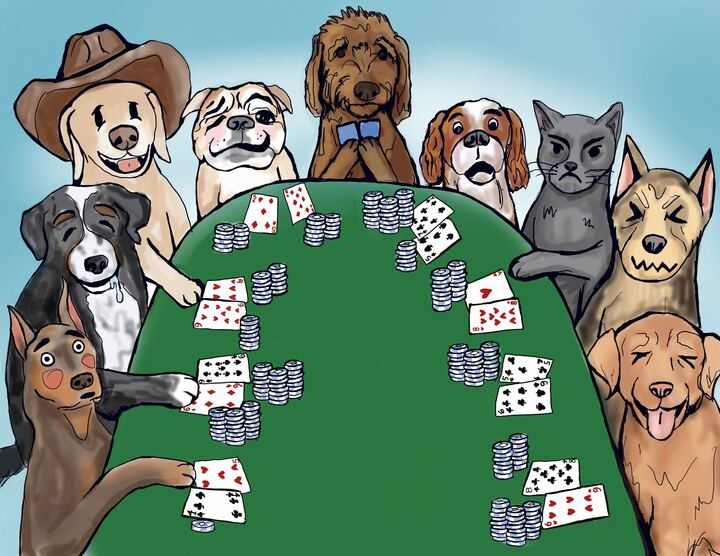

In [168]:
url='https://www.janestreet.com/puzzles/dogs-playing-poker-index/'
res = requests.get(url,verify=False)
soup = BeautifulSoup(res.content, 'html.parser')
x =[text for text in soup.body.stripped_strings]
#display([(i,j) for i,j in enumerate(x)])
display(Markdown(" ".join(x[15:19])))
display(Image('https://www.janestreet.com/puzzles/dogs-playing-poker.png',width=600))

In [170]:
clue = [['flushedface','4C5H',[1,0]],
        ['droolingface','6D9S',[22,23]], 
        ['cowboyhatface','9H4H',[7,12]],
        ['woozyface','5D8D',[10,11]],
        ['anguishedface','7C5S',[23,6]],
        ['poutingcat','1H8H',[16,0]] ,
        ['confoundedface','5C6C',[23,0]],
        ['squintingfacewithtongue','8C6H',[14,25]]
        ]

answer = []
answer2 = []
shift_letter = lambda ch, n: chr((ord(ch.lower()) - ord('a') + n) % 26 + ord('a'))
for emoji,cards,chips in clue:
    answer += [emoji[int(cards[0])-1]+emoji[int(cards[2])-1]]
    answer2 += [
        shift_letter(emoji[int(cards[0])-1],chips[0])+
        shift_letter(emoji[int(cards[2])-1],chips[1])
    ]

print("First Pass :","".join(answer))
print("After Chips :","".join(answer2))

First Pass : shiftbychipcount
After Chips : thecanineofclubs


In [172]:
# K9 of clubs => KC,9C

In [176]:
url='https://www.janestreet.com/puzzles/robot-road-trip-solution/'
res = requests.get(url,verify=False)
soup = BeautifulSoup(res.content, 'html.parser')
x =[text for text in soup.body.stripped_strings]
#display([(i,j) for i,j in enumerate(x)])
display(Markdown(" ".join(x[16:54])))

The trickiest part of this probability puzzle is determining the relative base rates
between cars of different speeds overtaking each other. The notes about how cars rarely
meet and all trips are the same long length N (made precise by taking limits) implies
that we can minimize the “first order term” of the cost of exactly two cars meeting and
we can ignore the boundary effects of meeting near the beginning or end of one of the
cars’ journeys. We know each car’s speed is uniformly chosen in [1,2], so to find the
relative rates of overtaking we can integrate over two speeds being drawn and then
consider the set of positions in distance and time (which we are also given as being
uniform) that the slower car would’ve had to start at to be overtaken by the faster car. So say the two speeds we select are u < v , and without loss of generality we fix the
position of the car traveling v to enter the highway at (0, 0) (the first coordinate is
in distance and the second is in time). Then the car will exit the highway at ( N , N/v ), and the starting positions of the u -speed car that need to be overtaken by the v -speed car are those within the pictured parallelogram (again we are ignoring weirdness
along the boundary because it will go to zero in the limit). A few different methods can
compute the area of this parallelogram to be N 2 (1/ u - 1/ v ). There are other ways
to reason out this base rate but I like drawing parallelograms. Now we must compute the cost of each overtake as a function of the speed of the overtaken
car, it turns out to be in proportion to the square of the difference between u and the
speed the car must reduce to. This implies we are trying to choose a to minimize the sum
of the integrals pictured. The first integral is the cost of reducing speed from the slow
lane to zero and the second integral is the cost of reducing speed from the fast lane to
the slow lane. The N 2 factors out and can be ignored, and some fundamental
theorem of calculus and integration computing can get to an expression in a whose
solution is 1.1771414168 … Congrats to all the solvers able to find the optimal speed limit!